# HGCTSVG Human Kidney Cancer Interface Data Preparation

## Contents
1. [Data Preparation: Loading and Processing](#Load-data)


In [1]:
import os
import matplotlib as mpl
import scanpy as sc

from pathlib import Path
from hgctsvg.preprocessing import common, image, kidneycancer

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Specify the input folder.

In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
patient_id = 'PD47171'

Specify the output folder.

In [3]:
spotiphy_proj_folder = Path("spotiphy_project_files/Human Kidney Cancer Interface/")
spotiphy_proj_folder.mkdir(parents=True, exist_ok=True)    

## Data Preparation: Loading and Processing <a id=Load-data></a>

Load the scRNA data and visium data.

In [4]:
adata_sc = sc.read_h5ad(data_dir / "RCC_upload_final_raw_counts.h5ad")
adata_st_inter = sc.read_h5ad(data_dir / "visium_merge_inter_upload.h5ad")

Extract the speciment of interest (patient PD47171) from the scRNA and visium data.

In [ ]:
# Extract data of patient PD47171
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)
adata_st_inter = kidneycancer.extract_st_patient_data(adata_st_inter, patient_id)

Format scRNA data to use ENSEMBLE gene ids as index to align it with the visium data.

In [6]:
# Format data to use ENSEMBL gene id as index
# necessary to align indexes of st and sc datasets

# TODO
# TMSB15B -> rename ENSG00000269226 to TMSB15C
# MATR3 -> drop ENS00000280987
# TBCE -> drop ENSG00000285053
adata_sc, adata_st_inter = common.use_ensembl_gene_ids(adata_sc, adata_st_inter, 
                                                 host="http://oct2022.archive.ensembl.org", 
                                                 drop_cols = ["ENSG00000280987", "ENSG00000285053"], 
                                                 rename_cols = {"ENSG00000269226": "TMSB15C"})

In [7]:
adata_sc.X.max(), adata_sc.X.mean()

(825.0, 0.18805256)

Extract the corresponding H&E staining image from the visium data

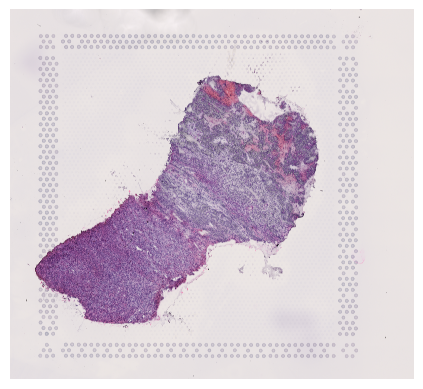

In [8]:
# Get ST image
img = image.get_image(adata_st_inter, scale=True)

# Plot without axes
mpl.pyplot.imshow(img)
mpl.pyplot.axis('off')  # Remove axis ticks and labels
mpl.pyplot.show()

Save the files prepared scRNA data, visium data, and image separately. These will be the inputs to Spotiphy.

In [9]:
adata_sc.write(spotiphy_proj_folder / 'Human Kidney Cancer scRNA Ref.h5ad')
adata_st_inter.write(spotiphy_proj_folder / 'Human Kidney Cancer Interface.h5ad')
img.save(spotiphy_proj_folder / 'Human Kidney Cancer Interface.tif')

In [10]:
interest_genes = ['NDRG1', 'RPL13', 'TMEM45A']


In [11]:
annot = sc.queries.biomart_annotations("hsapiens",
                                       ["ensembl_gene_id", 
                                        "external_gene_name",
                                        "gene_biotype",
                                        "chromosome_name"])
    

In [12]:
interest_gene_ensembl = annot[annot['external_gene_name'].isin(interest_genes)]['ensembl_gene_id'].tolist()

In [13]:
adata_sc = sc.read_h5ad(data_dir / "RCC_upload_final_raw_counts.h5ad")
adata_st_inter = sc.read_h5ad(data_dir / "visium_merge_inter_upload.h5ad")

In [14]:
adata_st_inter.var[adata_st_inter.var_names.isin(interest_gene_ensembl)]

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499406,mean_counts-6800STDY12499406,log1p_mean_counts-6800STDY12499406,pct_dropout_by_counts-6800STDY12499406,total_counts-6800STDY12499406,log1p_total_counts-6800STDY12499406,...,log1p_mean_counts-6800STDY12499508,pct_dropout_by_counts-6800STDY12499508,total_counts-6800STDY12499508,log1p_total_counts-6800STDY12499508,n_cells_by_counts-6800STDY12499509,mean_counts-6800STDY12499509,log1p_mean_counts-6800STDY12499509,pct_dropout_by_counts-6800STDY12499509,total_counts-6800STDY12499509,log1p_total_counts-6800STDY12499509
ENSEMBL,,,,,,,,,,,,,,,,,,,,,
ENSG00000181458,Gene Expression,GRCh38,TMEM45A,False,113,0.039379,0.038624,96.628878,132.0,4.890349,...,0.230254,79.512540,733.0,6.598509,574,0.255425,0.227474,79.580221,718.0,6.577861
ENSG00000104419,Gene Expression,GRCh38,NDRG1,False,1435,1.131265,0.756716,57.189737,3792.0,8.240912,...,1.258148,22.642176,7131.0,8.872347,1819,1.810388,1.033322,35.289932,5089.0,8.535033
ENSG00000167526,Gene Expression,GRCh38,RPL13,False,3168,15.031623,2.774563,5.489260,50386.0,10.827489,...,3.107082,1.059696,60458.0,11.009721,2797,15.827463,2.823012,0.498043,44491.0,10.703065


In [15]:
adata_sc.var[adata_sc.var['name'].isin(interest_genes)]

,name
TMEM45A,TMEM45A
NDRG1,NDRG1
RPL13,RPL13


In [16]:
adata_st_inter.obs

,in_tissue,array_row,array_col,sample,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,mt_frac,donor_id,region
spot_id,,,,,,,,,,,,,,,
6800STDY12499406_AAACAAGTATCTCCCA-1,1,50,102,6800STDY12499406,873,6.773080,1430.0,7.266129,29.160839,39.090909,52.937063,73.916084,0.064336,PD43824,g
6800STDY12499406_AAACACCAATAACTGC-1,1,59,19,6800STDY12499406,1666,7.418781,3531.0,8.169620,29.623336,39.563863,50.495610,66.978193,0.122345,PD43824,g
6800STDY12499406_AAACAGAGCGACTCCT-1,1,14,94,6800STDY12499406,1921,7.561122,4168.0,8.335431,23.560461,34.237044,45.873321,62.979846,0.022313,PD43824,g
6800STDY12499406_AAACAGGGTCTATATT-1,1,47,13,6800STDY12499406,1653,7.410952,3485.0,8.156510,29.641320,39.253945,49.641320,66.915352,0.122238,PD43824,g
6800STDY12499406_AAACAGTGTTCCTGGG-1,1,73,43,6800STDY12499406,1062,6.968850,2030.0,7.616283,29.704433,40.541872,52.660099,72.315271,0.032512,PD43824,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499509_TTGTTCAGTGTGCTAC-1,1,24,64,6800STDY12499509,770,6.647688,1953.0,7.577634,42.857143,56.886841,69.329237,86.175115,0.102407,PD47465,g
6800STDY12499509_TTGTTCTAGATACGCT-1,1,21,3,6800STDY12499509,4305,8.367765,13938.0,9.542446,25.742574,37.214808,47.818912,60.073181,0.064213,PD47465,g
6800STDY12499509_TTGTTGTGTGTCAAGA-1,1,31,77,6800STDY12499509,375,5.929589,512.0,6.240276,31.640625,46.289062,65.820312,100.000000,0.083984,PD47465,g


In [17]:
import squidpy as sq
sq.pl.spatial_scatter(adata_st_inter, color = interest_gene_ensembl)

ValueError: Found `library_id: `['spaceranger130_count_44214_6800STDY12499406_GRCh38-2020-A', 'spaceranger130_count_44214_6800STDY12499407_GRCh38-2020-A', 'spaceranger130_count_44214_6800STDY12499410_GRCh38-2020-A', 'spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A', 'spaceranger130_count_44215_6800STDY12499408_GRCh38-2020-A', 'spaceranger130_count_44215_6800STDY12499409_GRCh38-2020-A', 'spaceranger130_count_44215_6800STDY12499412_GRCh38-2020-A', 'spaceranger130_count_44215_6800STDY12499413_GRCh38-2020-A', 'spaceranger130_count_44316_6800STDY12499502_GRCh38-2020-A', 'spaceranger130_count_44316_6800STDY12499503_GRCh38-2020-A', 'spaceranger130_count_44316_6800STDY12499504_GRCh38-2020-A', 'spaceranger130_count_44316_6800STDY12499505_GRCh38-2020-A', 'spaceranger130_count_44317_6800STDY12499506_GRCh38-2020-A', 'spaceranger130_count_44317_6800STDY12499507_GRCh38-2020-A', 'spaceranger130_count_44317_6800STDY12499508_GRCh38-2020-A', 'spaceranger130_count_44317_6800STDY12499509_GRCh38-